# Oral Cavity Segmentation — Mobile-UNet Stage 2: Fine-Tuning Strategy Comparison

This notebook performs **Stage 2 only**.

The starting point is the **exact trained Stage-1 winner `hp_bs_16` checkpoint**. No new baseline is trained in this notebook.

### Stage-2 strategies
1. **Head only** — freeze the entire existing Mobile-UNet and train only `head_out`.
2. **Top layers** — freeze the first two encoder stages (`enc0`, `enc1`) and fine-tune the remaining original network.
3. **Full unfrozen** — fine-tune the entire original Mobile-UNet.
4. **Adapters** — add lightweight residual adapters, freeze the original Mobile-UNet weights, and train only adapters + `head_out`.

All four experiments use the **same Stage-1 configuration** and the **same 10-epoch budget**. Each strategy gets its own fresh model initialized from the same Stage-1 checkpoint, so one strategy cannot affect another.

The data pipeline, mask creation, train/validation split, augmentation, architecture, loss, and metrics are kept consistent with Stage 1.


### Checkpoint input
The notebook accepts the Stage-1 winner checkpoint under either:
- `hp_bs_16_best.weights.h5`
- `hp_bs_16_best.weights (1).h5`

Therefore, the Kaggle-uploaded `(1)` filename does not need to be renamed.


## 1. Environment Check

In [1]:
import sys, platform
import tensorflow as tf

print("Python:", sys.version)
print("Platform:", platform.platform())
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))


Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
Platform: Linux-6.12.90+-x86_64-with-glibc2.35
TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Kaggle Input Check

In [2]:
import os
print("Available Kaggle input datasets:")
for d in os.listdir("/kaggle/input"):
    print(" -", d)


Available Kaggle input datasets:
 - datasets


## Imports

In [3]:
import os
import json
import random
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models, backend as K

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


## Config & Output Folder

In [4]:
# ============================================================
# STAGE 2 CONFIGURATION
# ============================================================
# Stage 2 starts ONLY from the selected Stage-1 model: hp_bs_16.
# It does NOT retrain the baseline and does NOT start from mobile_unet.

MODEL_NAME = "mobile_unet"
OUTPUT_DIR = Path("/kaggle/working/Segmentation Output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MASKS_DIR = OUTPUT_DIR / "masks"
MASKS_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR = OUTPUT_DIR / f"{MODEL_NAME}_results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
EXP_DIR = OUTPUT_DIR / "stage2_finetuning_experiments"
EXP_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 256
SELECTED_MODEL = "hp_bs_16"
BASE_FILTERS = 16
DEPTH = 4
USE_SE = False
DROPOUT_RATE = 0.0
WEIGHT_DECAY = 0.0
LEARNING_RATE = 1e-5
BATCH_SIZE = 16
STAGE2_EPOCHS = 10

# Leave empty for automatic discovery.
STAGE1_CHECKPOINT_OVERRIDE = ""
RESUME_EXISTING = True

STRATEGIES = ["head_only", "top_layers", "full_unfrozen", "adapters"]

print("Stage 2 selected model:", SELECTED_MODEL)
print("Configuration:")
print("  base_filters:", BASE_FILTERS)
print("  depth:", DEPTH)
print("  batch_size:", BATCH_SIZE)
print("  learning_rate:", LEARNING_RATE)
print("  dropout:", DROPOUT_RATE)
print("  weight_decay:", WEIGHT_DECAY)
print("  epochs per strategy:", STAGE2_EPOCHS)
print("Output folder:", OUTPUT_DIR)
print("Stage-2 folder:", EXP_DIR)


Stage 2 selected model: hp_bs_16
Configuration:
  base_filters: 16
  depth: 4
  batch_size: 16
  learning_rate: 1e-05
  dropout: 0.0
  weight_decay: 0.0
  epochs per strategy: 10
Output folder: /kaggle/working/Segmentation Output
Stage-2 folder: /kaggle/working/Segmentation Output/stage2_finetuning_experiments


## 2. Dataset `Categories` Folder

In [5]:
DATASET_DIR = Path(
    "/kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project"
)

print("Categories folder:", DATASET_DIR)
print("Exists:", DATASET_DIR.exists())


Categories folder: /kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project
Exists: True


## 3. COCO Annotation JSON

In [6]:
ANNOTATION_FILE = Path(
    "/kaggle/input/datasets/annapoornaak/metadata-zenodo/Annotation.json"
)

print("Annotation file:", ANNOTATION_FILE)
print("Exists:", ANNOTATION_FILE.exists())


Annotation file: /kaggle/input/datasets/annapoornaak/metadata-zenodo/Annotation.json
Exists: True


## 4. Load & Verify `Lesion` and `Oral Cavity` Categories

In [7]:
with open(ANNOTATION_FILE, "r") as f:
    coco = json.load(f)

print("Images:", len(coco["images"]))
print("Annotations:", len(coco["annotations"]))
print("Categories:", coco["categories"])

name_to_id = {c["name"]: c["id"] for c in coco["categories"]}
assert "Lesion" in name_to_id, "Lesion category not found"
assert "Oral Cavity" in name_to_id, "Oral Cavity category not found"

CATEGORY_ID_LESION = name_to_id["Lesion"]
CATEGORY_ID_ORAL = name_to_id["Oral Cavity"]

print("Lesion id:", CATEGORY_ID_LESION)
print("Oral Cavity id:", CATEGORY_ID_ORAL)

category_counts = Counter(ann["category_id"] for ann in coco["annotations"])
for c in coco["categories"]:
    print(c["name"], "->", category_counts[c["id"]], "annotations")


Images: 3000
Annotations: 6358
Categories: [{'id': 1, 'name': 'Lesion', 'supercategory': 'object'}, {'id': 2, 'name': 'Oral Cavity', 'supercategory': 'object'}]
Lesion id: 1
Oral Cavity id: 2
Lesion -> 3358 annotations
Oral Cavity -> 3000 annotations


## 5. Match Annotation Images to Category Folders

In [8]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

filename_to_path = {}
for path in DATASET_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in image_extensions:
        filename_to_path[path.name] = path

images_info = {img["id"]: img for img in coco["images"]}

matched, unmatched = 0, 0
image_id_to_path = {}

for image_id, info in images_info.items():
    fname = Path(info["file_name"]).name
    if fname in filename_to_path:
        image_id_to_path[image_id] = filename_to_path[fname]
        matched += 1
    else:
        unmatched += 1

print("Matched:", matched)
print("Unmatched:", unmatched)


Matched: 3000
Unmatched: 0


## 6. Create Oral Cavity Binary Masks

In [9]:
oral_annotations_by_image = {}
for ann in coco["annotations"]:
    if ann["category_id"] != CATEGORY_ID_ORAL:
        continue
    oral_annotations_by_image.setdefault(ann["image_id"], []).append(ann)

print("Images with oral cavity annotations:", len(oral_annotations_by_image))

def create_oral_cavity_mask(image_id):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        return None

    image = cv2.imread(str(image_path))
    if image is None:
        return None

    height, width = image.shape[:2]
    mask = np.zeros((height, width), dtype=np.uint8)

    for ann in oral_annotations_by_image.get(image_id, []):
        segmentation = ann.get("segmentation", [])
        if not segmentation:
            continue

        if isinstance(segmentation[0], (int, float)):
            polygons = [segmentation]
        else:
            polygons = segmentation

        for polygon in polygons:
            if len(polygon) < 6:
                continue

            points = np.array(polygon, dtype=np.float32).reshape(-1, 2)
            points = np.round(points).astype(np.int32)

            points[:, 0] = np.clip(points[:, 0], 0, width - 1)
            points[:, 1] = np.clip(points[:, 1], 0, height - 1)

            cv2.fillPoly(mask, [points], 255)

    return mask

test_image_id = list(oral_annotations_by_image.keys())[0]
test_mask = create_oral_cavity_mask(test_image_id)
print("Test image ID:", test_image_id)
print("Mask shape:", test_mask.shape)
print("Unique values:", np.unique(test_mask))


Images with oral cavity annotations: 2999
Test image ID: 1
Mask shape: (3456, 4608)
Unique values: [  0 255]


## 7. Generate Complete Image-Mask Dataset

In [10]:
from tqdm import tqdm
records = []

for image_id in tqdm(list(oral_annotations_by_image.keys())):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        continue

    mask = create_oral_cavity_mask(image_id)
    if mask is None:
        continue

    mask_path = MASKS_DIR / f"{image_id}.png"
    cv2.imwrite(str(mask_path), mask)

    records.append({
        "image_id": image_id,
        "image_path": str(image_path),
        "mask_path": str(mask_path),
    })

dataset_df = pd.DataFrame(records)
dataset_df.to_csv(OUTPUT_DIR / "dataset_index.csv", index=False)

print("Total image-mask pairs:", len(dataset_df))
dataset_df.head()


100%|██████████| 2999/2999 [06:38<00:00,  7.52it/s]


Total image-mask pairs: 2999


,image_id,image_path,mask_path
0,1,/kaggle/input/datasets/annapoornaak/oral-cance...,/kaggle/working/Segmentation Output/masks/1.png
1,2,/kaggle/input/datasets/annapoornaak/oral-cance...,/kaggle/working/Segmentation Output/masks/2.png
2,3,/kaggle/input/datasets/annapoornaak/oral-cance...,/kaggle/working/Segmentation Output/masks/3.png
3,4,/kaggle/input/datasets/annapoornaak/oral-cance...,/kaggle/working/Segmentation Output/masks/4.png
4,5,/kaggle/input/datasets/annapoornaak/oral-cance...,/kaggle/working/Segmentation Output/masks/5.png


## 8. 80/20 Train-Validation Split

In [11]:
train_df, val_df = train_test_split(dataset_df, test_size=0.2, random_state=SEED)
print("Train:", len(train_df))
print("Val:", len(val_df))


Train: 2399
Val: 600


## 9. Paired Image + Mask Augmentation Pipeline

In [12]:
def load_image_mask(image_path, mask_path):
    image_path = image_path.numpy().decode("utf-8")
    mask_path = mask_path.numpy().decode("utf-8")

    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    image = image.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)

    return image, mask

def tf_load_image_mask(image_path, mask_path):
    image, mask = tf.py_function(
        func=load_image_mask,
        inp=[image_path, mask_path],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask

def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)

    k = tf.random.uniform((), 0, 4, dtype=tf.int32)
    image = tf.image.rot90(image, k)
    mask = tf.image.rot90(mask, k)

    image = tf.image.random_brightness(image, 0.15)
    image = tf.image.random_contrast(image, 0.85, 1.15)
    image = tf.clip_by_value(image, 0.0, 1.0)

    return image, mask

def make_dataset(df, training, batch_size=BATCH_SIZE):
    """General-purpose dataset builder, parameterized by batch size so the
    hyperparameter sweeps later can vary it."""
    paths = (df["image_path"].values, df["mask_path"].values)
    ds = tf.data.Dataset.from_tensor_slices(paths)
    ds = ds.map(tf_load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.shuffle(256)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)

for img_batch, mask_batch in train_ds.take(1):
    print("Image batch:", img_batch.shape)
    print("Mask batch:", mask_batch.shape)


I0000 00:00:1789667464.228566      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789667464.231443      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Image batch: (16, 256, 256, 3)
Mask batch: (16, 256, 256, 1)


## Sanity Check: Corrupted Images

In [13]:
from PIL import Image

bad_images = []
for idx, row in dataset_df.iterrows():
    image_path = row["image_path"]
    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception as e:
        bad_images.append({"image_id": row["image_id"], "image_path": image_path, "error": str(e)})

print("Total image-mask pairs:", len(dataset_df))
print("Corrupted images:", len(bad_images))

if bad_images:
    bad_df = pd.DataFrame(bad_images)
    display(bad_df)
else:
    print("No corrupted images found.")


Total image-mask pairs: 2999
Corrupted images: 0
No corrupted images found.


## 10. Loss & Metrics

In [14]:
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def iou_coef(y_true, y_pred, smooth=1.0):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)


## 11. Unified, Explicitly-Named Mobile-UNet Builder

A depthwise separable conv splits a normal convolution into two cheap steps: one filter
*per channel* (spatial), then a `1x1` conv to mix channels - the MobileNet trick, same
receptive field at a fraction of the cost.

Every layer here gets a stable name (`enc{i}_...`, `bottleneck_...`, `dec{i}_...`,
`head_...`, `..._adapter`) so later sections can freeze specific layers by name prefix and
transfer matching baseline weights safely. Supports optional SE (attention) blocks, adapter modules, a
swappable "enhanced" head, and bottleneck dropout - this ONE function builds the baseline
and every fine-tuned/lightweight variant that follows.

In [15]:
def sep_conv_bn_relu(x, filters, name, kernel=3, strides=1):
    x = layers.SeparableConv2D(filters, kernel, strides=strides, padding="same",
                                use_bias=False, name=f"{name}_sepconv")(x)
    x = layers.BatchNormalization(name=f"{name}_bn")(x)
    x = layers.Activation("relu", name=f"{name}_relu")(x)
    return x

def se_block(x, filters, name, ratio=8):
    se = layers.GlobalAveragePooling2D(name=f"{name}_gap")(x)
    se = layers.Dense(max(filters // ratio, 4), activation="relu", name=f"{name}_fc1")(se)
    se = layers.Dense(filters, activation="sigmoid", name=f"{name}_fc2")(se)
    se = layers.Reshape((1, 1, filters), name=f"{name}_reshape")(se)
    return layers.Multiply(name=f"{name}_scale")([x, se])

def adapter_block(x, filters, name, bottleneck_ratio=4):
    """Small trainable bottleneck injected after a block, base weights untouched.
    reduce -> expand -> residual add; zero-init on expand means it starts as an identity."""
    reduced = max(filters // bottleneck_ratio, 4)
    a = layers.Conv2D(reduced, 1, activation="relu", name=f"{name}_adapter_reduce")(x)
    a = layers.Conv2D(filters, 1, name=f"{name}_adapter_expand", kernel_initializer="zeros")(a)
    return layers.Add(name=f"{name}_adapter_add")([x, a])

def build_mobile_unet(input_shape, base_filters=16, depth=4, use_se=False,
                       use_adapters=False, dropout_rate=0.0, head_type="simple",
                       name="mobile_unet"):
    inputs = layers.Input(shape=input_shape)
    x = inputs
    skips = []
    filters = base_filters

    # ---- Encoder ----
    for i in range(depth):
        stage = f"enc{i}"
        x = sep_conv_bn_relu(x, filters, name=f"{stage}_a")
        x = sep_conv_bn_relu(x, filters, name=f"{stage}_b")
        if use_se:
            x = se_block(x, filters, name=f"{stage}_se")
        if use_adapters:
            x = adapter_block(x, filters, name=stage)
        skips.append(x)
        x = layers.MaxPooling2D(2, name=f"{stage}_pool")(x)
        filters *= 2

    # ---- Bottleneck ----
    x = sep_conv_bn_relu(x, filters, name="bottleneck_a")
    x = sep_conv_bn_relu(x, filters, name="bottleneck_b")
    if use_adapters:
        x = adapter_block(x, filters, name="bottleneck")
    if dropout_rate > 0:
        x = layers.SpatialDropout2D(dropout_rate, name="bottleneck_dropout")(x)

    # ---- Decoder ----
    for i in reversed(range(depth)):
        stage = f"dec{i}"
        filters //= 2
        x = layers.UpSampling2D(2, interpolation="bilinear", name=f"{stage}_up")(x)
        x = layers.Concatenate(name=f"{stage}_concat")([x, skips[i]])
        x = sep_conv_bn_relu(x, filters, name=f"{stage}_a")
        x = sep_conv_bn_relu(x, filters, name=f"{stage}_b")
        if use_adapters:
            x = adapter_block(x, filters, name=stage)

    # ---- Head (swappable) ----
    if head_type == "enhanced":
        x = sep_conv_bn_relu(x, base_filters, name="head_pre")
    outputs = layers.Conv2D(1, 1, activation="sigmoid", name="head_out")(x)

    return models.Model(inputs, outputs, name=name)


## Stage 2 checkpoint requirement

Before any training starts, the notebook locates the exact Stage-1 checkpoint:

`hp_bs_16_best.weights.h5`

The notebook stops instead of guessing if it cannot find the checkpoint or if it finds multiple ambiguous copies.


In [16]:
# ============================================================
# STAGE 2 CHECKPOINT DISCOVERY — FAIL SAFE
# ============================================================
# IMPORTANT:
# The Stage-1 checkpoint was uploaded to Kaggle with the filename:
#     hp_bs_16_best.weights (1).h5
#
# We therefore accept BOTH the original name and Kaggle's "(1)" name.
# No renaming of the Kaggle file is required.
#
# The notebook will:
#   1. Prefer an explicitly supplied override path if provided.
#   2. Otherwise search /kaggle/working and /kaggle/input recursively.
#   3. Accept ONLY the two exact approved filenames below.
#   4. Refuse to guess if multiple approved checkpoints are found.

import hashlib

EXPECTED_CHECKPOINT_NAME = f"{SELECTED_MODEL}_best.weights.h5"
ACCEPTED_CHECKPOINT_NAMES = {
    EXPECTED_CHECKPOINT_NAME,
    f"{SELECTED_MODEL}_best.weights (1).h5",
}

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()


def find_stage1_checkpoint():
    # --------------------------------------------------------
    # 1. Explicit override, if the user wants to provide one.
    # --------------------------------------------------------
    if STAGE1_CHECKPOINT_OVERRIDE.strip():
        p = Path(STAGE1_CHECKPOINT_OVERRIDE).expanduser()

        if not p.exists():
            raise FileNotFoundError(
                "STAGE1_CHECKPOINT_OVERRIDE does not exist:\n"
                f"{p}"
            )

        if p.name not in ACCEPTED_CHECKPOINT_NAMES:
            raise ValueError(
                "The override must point to one of these approved Stage-1 "
                "checkpoint filenames:\n"
                + "\n".join(f"  - {name}" for name in sorted(ACCEPTED_CHECKPOINT_NAMES))
                + f"\n\nReceived: {p.name}"
            )

        return p.resolve()

    # --------------------------------------------------------
    # 2. Automatic recursive search.
    # --------------------------------------------------------
    roots = [Path("/kaggle/working"), Path("/kaggle/input")]
    matches = []

    for root in roots:
        if not root.exists():
            continue

        for candidate_name in ACCEPTED_CHECKPOINT_NAMES:
            matches.extend(root.rglob(candidate_name))

    # Remove duplicate paths.
    unique = []
    seen = set()

    for p in matches:
        try:
            rp = p.resolve()
        except Exception:
            rp = p

        key = str(rp)
        if key not in seen:
            seen.add(key)
            unique.append(rp)

    # --------------------------------------------------------
    # 3. Nothing found -> stop BEFORE any Stage-2 training.
    # --------------------------------------------------------
    if len(unique) == 0:
        raise FileNotFoundError(
            "Stage-1 winner checkpoint was not found.\n\n"
            "The notebook searched recursively in:\n"
            "  /kaggle/working\n"
            "  /kaggle/input\n\n"
            "Accepted filenames are:\n"
            + "\n".join(f"  - {name}" for name in sorted(ACCEPTED_CHECKPOINT_NAMES))
            + "\n\n"
            "Make sure the Kaggle Dataset containing "
            "'hp_bs_16_best.weights (1).h5' is attached under Input."
        )

    # --------------------------------------------------------
    # 4. If multiple copies exist, prefer the exact original
    #    filename over the "(1)" duplicate.
    # --------------------------------------------------------
    exact_name_matches = [
        p for p in unique
        if p.name == EXPECTED_CHECKPOINT_NAME
    ]

    if len(exact_name_matches) == 1:
        return exact_name_matches[0]

    if len(unique) == 1:
        return unique[0]

    # Prefer the exact Stage-1 experiment folder if available.
    canonical = [
        p for p in unique
        if "finetuning_experiments" in str(p)
        and p.parent.name == SELECTED_MODEL
    ]

    if len(canonical) == 1:
        return canonical[0]

    listing = "\n".join(f"  - {p}" for p in unique)
    raise RuntimeError(
        "Multiple approved Stage-1 checkpoints were found and the notebook "
        "refuses to guess.\n\n"
        + listing
        + "\n\n"
        "Set STAGE1_CHECKPOINT_OVERRIDE to the exact checkpoint you want to use."
    )


STAGE1_CHECKPOINT = find_stage1_checkpoint()
STAGE1_SHA256 = sha256_file(STAGE1_CHECKPOINT)

print("=" * 80)
print("STAGE 2 — EXACT STAGE-1 CHECKPOINT FOUND")
print("=" * 80)
print("Selected model       :", SELECTED_MODEL)
print("Checkpoint           :", STAGE1_CHECKPOINT)
print("Checkpoint filename  :", STAGE1_CHECKPOINT.name)
print("Checkpoint exists    :", STAGE1_CHECKPOINT.exists())
print("Checkpoint size (MB) :", round(
    STAGE1_CHECKPOINT.stat().st_size / (1024 * 1024), 3
))
print("SHA-256              :", STAGE1_SHA256)
print("=" * 80)

assert STAGE1_CHECKPOINT.exists()
assert STAGE1_CHECKPOINT.name in ACCEPTED_CHECKPOINT_NAMES


STAGE 2 — EXACT STAGE-1 CHECKPOINT FOUND
Selected model       : hp_bs_16
Checkpoint           : /kaggle/input/datasets/annn51/mobile-unet-stage1-best/hp_bs_16_best.weights (1).h5
Checkpoint filename  : hp_bs_16_best.weights (1).h5
Checkpoint exists    : True
Checkpoint size (MB) : 2.94
SHA-256              : 94858fbcd9fa86762a4099e2578a668bb853185a8d352de1a085610634efaea4


## Stage 2 model initialization and freezing rules

Every strategy is created as a fresh model and initialized from the same Stage-1 checkpoint.

`head_only` keeps the original `head_out`; it does not change the head architecture.


In [17]:
import re

# ============================================================
# STAGE 2 TRAINING UTILITIES — VERIFIED CHECKPOINT LOADER
# ============================================================
# IMPORTANT:
# The uploaded Stage-1 file is a Keras-3 `.weights.h5` file.  It contains
# the Keras-3 `layers/` hierarchy, not the legacy HDF5 `layer_names` layout.
# Therefore we do NOT call the legacy HDF5 loader on this file.
# We read the 37 weighted Stage-1 layers from the Keras-3 hierarchy and
# transfer them to the identically shaped Stage-2 base model.

class TimeHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self._epoch_start = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self._epoch_start)


def reset_random_seeds():
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)


def model_size_mb(path):
    return os.path.getsize(path) / (1024 * 1024)


def _natural_layer_names(layer_group, base_name):
    """Return exact Keras-3 group names in numeric order.

    Example:
        separable_conv2d, separable_conv2d_1, ..., separable_conv2d_17

    This intentionally avoids the previous regex bug that treated `_1`, `_2`,
    etc. incorrectly.
    """
    names = []
    for raw_name in layer_group.keys():
        name = str(raw_name)
        if name == base_name:
            names.append((0, name))
        else:
            prefix = base_name + "_"
            suffix = name[len(prefix):] if name.startswith(prefix) else None
            if suffix is not None and suffix.isdigit():
                names.append((int(suffix), name))
    names.sort(key=lambda item: item[0])

    # Detect duplicate/missing numbering rather than silently guessing.
    indices = [idx for idx, _ in names]
    expected = list(range(len(indices)))
    if indices != expected:
        raise RuntimeError(
            f"Unexpected numbering for {base_name}: found indices {indices}, "
            f"expected {expected}."
        )
    return [name for _, name in names]


def _h5_layer_group_names(h5_file):
    """Read the Keras-3 weighted-layer groups from the uploaded H5 file."""
    if "layers" not in h5_file:
        raise RuntimeError("Checkpoint is missing the Keras-3 `layers` group.")

    groups = h5_file["layers"]
    return {
        "SeparableConv2D": _natural_layer_names(groups, "separable_conv2d"),
        "BatchNormalization": _natural_layer_names(groups, "batch_normalization"),
        "Conv2D": _natural_layer_names(groups, "conv2d"),
    }


def _read_h5_layer_weights(group):
    """Read numeric vars/0, vars/1, ... arrays from one Keras-3 layer group."""
    if "vars" not in group:
        return []
    var_group = group["vars"]
    keys = list(var_group.keys())
    if not all(str(k).isdigit() for k in keys):
        raise RuntimeError(f"Non-numeric weight keys found: {keys}")
    keys = sorted(keys, key=lambda x: int(x))
    return [np.array(var_group[k]) for k in keys]


def load_exact_stage1_weights(model, checkpoint_path):
    """Transfer the exact Stage-1 hp_bs_16 weights into a base Mobile-UNet.

    Expected Stage-1 topology:
      18 SeparableConv2D + 18 BatchNormalization + 1 Conv2D = 37 weighted layers.

    Adapter layers are intentionally excluded because adapters are new Stage-2
    parameters and must start from their own initialization.
    """
    import h5py

    weighted_layers = [
        layer for layer in model.layers
        if layer.get_weights() and "_adapter_" not in layer.name
    ]

    if len(weighted_layers) != 37:
        raise RuntimeError(
            f"Stage-1 topology check failed: expected 37 weighted layers, "
            f"but the Stage-2 base model has {len(weighted_layers)}."
        )

    with h5py.File(str(checkpoint_path), "r") as h5:
        groups = _h5_layer_group_names(h5)

        expected_counts = {
            "SeparableConv2D": 18,
            "BatchNormalization": 18,
            "Conv2D": 1,
        }
        for class_name, expected in expected_counts.items():
            actual = len(groups[class_name])
            if actual != expected:
                raise RuntimeError(
                    f"Checkpoint topology mismatch for {class_name}: "
                    f"expected {expected}, found {actual}."
                )

        counters = {name: 0 for name in expected_counts}
        copied = []

        for target_layer in weighted_layers:
            class_name = target_layer.__class__.__name__
            if class_name not in counters:
                raise RuntimeError(
                    f"Unexpected weighted layer type: {class_name} "
                    f"({target_layer.name})"
                )

            idx = counters[class_name]
            saved_name = groups[class_name][idx]
            saved_weights = _read_h5_layer_weights(h5["layers"][saved_name])
            target_weights = target_layer.get_weights()

            if len(saved_weights) != len(target_weights):
                raise RuntimeError(
                    f"Weight-count mismatch for {target_layer.name}: "
                    f"checkpoint {saved_name} has {len(saved_weights)} arrays, "
                    f"target has {len(target_weights)}."
                )

            for j, (saved, target) in enumerate(zip(saved_weights, target_weights)):
                if tuple(saved.shape) != tuple(target.shape):
                    raise RuntimeError(
                        f"Weight-shape mismatch for {target_layer.name}, variable {j}: "
                        f"checkpoint {saved.shape}, target {target.shape}. "
                        f"This means the Stage-2 architecture is NOT identical to Stage-1."
                    )

            target_layer.set_weights(saved_weights)
            copied.append(target_layer.name)
            counters[class_name] += 1

        # Final accounting: every expected weighted layer was consumed exactly once.
        if any(counters[k] != expected_counts[k] for k in counters):
            raise RuntimeError(f"Checkpoint loading incomplete: {counters}")

    print("Keras-3 HDF5 checkpoint loaded successfully.")
    print("  SeparableConv2D copied: 18/18")
    print("  BatchNormalization copied: 18/18")
    print("  Conv2D copied: 1/1")
    print("  Total weighted layers copied: 37/37")
    return copied


def set_strategy_trainability(model, strategy):
    # Freeze everything first. Each strategy explicitly enables only what it needs.
    for layer in model.layers:
        layer.trainable = False

    if strategy == "head_only":
        model.get_layer("head_out").trainable = True

    elif strategy == "top_layers":
        for layer in model.layers:
            if not (layer.name.startswith("enc0") or layer.name.startswith("enc1")):
                layer.trainable = True

    elif strategy == "full_unfrozen":
        for layer in model.layers:
            layer.trainable = True

    elif strategy == "adapters":
        for layer in model.layers:
            if "adapter" in layer.name or layer.name == "head_out":
                layer.trainable = True

    else:
        raise ValueError(f"Unknown Stage-2 strategy: {strategy}")


def assert_strategy_trainability(model, strategy):
    trainable = [layer.name for layer in model.layers if layer.trainable]

    if strategy == "head_only":
        assert trainable == ["head_out"], (
            "HEAD-ONLY ERROR: unexpected trainable layers: " + str(trainable)
        )

    elif strategy == "top_layers":
        assert not any(name.startswith("enc0") or name.startswith("enc1") for name in trainable)
        assert "head_out" in trainable

    elif strategy == "full_unfrozen":
        weighted = [layer.name for layer in model.layers if layer.get_weights()]
        trainable_weighted = [
            layer.name for layer in model.layers
            if layer.trainable and layer.get_weights()
        ]
        assert trainable_weighted == weighted, (
            "FULL-UNFROZEN ERROR: not all weighted layers are trainable."
        )

    elif strategy == "adapters":
        assert "head_out" in trainable
        adapter_layers = [name for name in trainable if "adapter" in name]
        assert adapter_layers, "ADAPTER ERROR: no adapter layers are trainable."
        unexpected = [
            name for name in trainable
            if "adapter" not in name and name != "head_out"
        ]
        assert not unexpected, (
            "ADAPTER ERROR: original layers became trainable: " + str(unexpected)
        )


def build_stage2_model(strategy):
    model = build_mobile_unet(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        base_filters=BASE_FILTERS,
        depth=DEPTH,
        use_se=USE_SE,
        use_adapters=(strategy == "adapters"),
        dropout_rate=DROPOUT_RATE,
        head_type="simple",
        name=f"stage2_{strategy}",
    )

    # Load Stage-1 base weights BEFORE applying the Stage-2 trainability policy.
    load_exact_stage1_weights(model, STAGE1_CHECKPOINT)
    set_strategy_trainability(model, strategy)
    assert_strategy_trainability(model, strategy)
    return model


## Pre-flight checkpoint test

The next cell evaluates `hp_bs_16` on the validation set before any Stage-2 training. If the checkpoint cannot be loaded, the notebook stops before GPU training.


In [18]:
# ============================================================
# PRE-FLIGHT — VERIFY STAGE-1 WINNER BEFORE ANY STAGE-2 TRAINING
# ============================================================
# This cell is intentionally expensive only at validation time and runs BEFORE
# all four Stage-2 training jobs. If anything is wrong, execution stops here.

EXPECTED_STAGE1_DICE = 0.942168
EXPECTED_STAGE1_IOU = 0.890891
PREFLIGHT_TOLERANCE = 0.02

reset_random_seeds()
preflight_model = build_mobile_unet(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    base_filters=BASE_FILTERS,
    depth=DEPTH,
    use_se=USE_SE,
    use_adapters=False,
    dropout_rate=DROPOUT_RATE,
    head_type="simple",
    name="stage1_hp_bs_16_preflight",
)

load_exact_stage1_weights(preflight_model, STAGE1_CHECKPOINT)
preflight_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=combined_loss,
    metrics=[dice_coef, iou_coef],
)

preflight_metrics = preflight_model.evaluate(
    val_ds, verbose=1, return_dict=True
)
preflight_dice = float(preflight_metrics["dice_coef"])
preflight_iou = float(preflight_metrics["iou_coef"])

print("\n" + "=" * 80)
print("STAGE-1 CHECKPOINT PREFLIGHT RESULT")
print("=" * 80)
print(f"Val loss : {preflight_metrics['loss']:.6f}")
print(f"Val Dice : {preflight_dice:.6f}")
print(f"Val IoU  : {preflight_iou:.6f}")
print(f"Expected : Dice {EXPECTED_STAGE1_DICE:.6f} | IoU {EXPECTED_STAGE1_IOU:.6f}")
print(f"Allowed  : +/- {PREFLIGHT_TOLERANCE:.3f}")

if abs(preflight_dice - EXPECTED_STAGE1_DICE) > PREFLIGHT_TOLERANCE:
    raise RuntimeError(
        "PREFLIGHT FAILED: loaded checkpoint does not reproduce the expected "
        f"Stage-1 Dice. Got {preflight_dice:.6f}, expected about "
        f"{EXPECTED_STAGE1_DICE:.6f}. NO Stage-2 training was started."
    )
if abs(preflight_iou - EXPECTED_STAGE1_IOU) > PREFLIGHT_TOLERANCE:
    raise RuntimeError(
        "PREFLIGHT FAILED: loaded checkpoint does not reproduce the expected "
        f"Stage-1 IoU. Got {preflight_iou:.6f}, expected about "
        f"{EXPECTED_STAGE1_IOU:.6f}. NO Stage-2 training was started."
    )

print("\nPREFLIGHT PASSED — Stage-1 checkpoint is compatible and reproduces the expected range.")
print("No Stage-2 training has occurred yet.")

del preflight_model
K.clear_session()


Keras-3 HDF5 checkpoint loaded successfully.
  SeparableConv2D copied: 18/18
  BatchNormalization copied: 18/18
  Conv2D copied: 1/1
  Total weighted layers copied: 37/37


2026-09-17 17:51:51.636464: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 17:51:51.802840: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 17:51:51.954348: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1789667516.840141      71 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


37/38 ━━━━━━━━━━━━━━━━━━━━ 0s 963ms/step - dice_coef: 0.9440 - iou_coef: 0.8941 - loss: 0.1718

2026-09-17 17:52:44.647020: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 17:52:44.809966: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 17:52:44.951035: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


38/38 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - dice_coef: 0.9422 - iou_coef: 0.8909 - loss: 0.1859

STAGE-1 CHECKPOINT PREFLIGHT RESULT
Val loss : 0.185895
Val Dice : 0.942168
Val IoU  : 0.890891
Expected : Dice 0.942168 | IoU 0.890891
Allowed  : +/- 0.020

PREFLIGHT PASSED — Stage-1 checkpoint is compatible and reproduces the expected range.
No Stage-2 training has occurred yet.


In [19]:
# ============================================================
# STAGE 2 DRY-RUN — VALIDATE ALL FOUR STRATEGIES BEFORE TRAINING
# ============================================================
# This catches model construction, checkpoint transfer, trainability, compile,
# and one forward pass for every strategy before spending hours on fit().

print("=" * 80)
print("STAGE 2 DRY-RUN: VALIDATING ALL FOUR STRATEGIES")
print("=" * 80)

# One real validation batch. No gradients and no training.
dry_batch = next(iter(val_ds))
dry_images, dry_masks = dry_batch

for strategy in STRATEGIES:
    print(f"\n[DRY-RUN] {strategy}")
    reset_random_seeds()
    dry_model = build_stage2_model(strategy)

    total_params = int(dry_model.count_params())
    trainable_params = int(sum(K.count_params(w) for w in dry_model.trainable_weights))
    if trainable_params <= 0:
        raise RuntimeError(f"{strategy}: zero trainable parameters.")

    dry_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=combined_loss,
        metrics=[dice_coef, iou_coef],
    )

    pred = dry_model(dry_images, training=False)
    if tuple(pred.shape) != tuple(dry_masks.shape):
        raise RuntimeError(
            f"{strategy}: output shape {tuple(pred.shape)} does not match "
            f"mask shape {tuple(dry_masks.shape)}."
        )
    if not np.all(np.isfinite(pred.numpy())):
        raise RuntimeError(f"{strategy}: forward pass produced non-finite values.")

    print(f"  Output shape       : {tuple(pred.shape)}")
    print(f"  Total params       : {total_params:,}")
    print(f"  Trainable params   : {trainable_params:,}")
    print("  Checkpoint transfer: PASS")
    print("  Trainability       : PASS")
    print("  Compile            : PASS")
    print("  Forward pass       : PASS")

    del dry_model
    K.clear_session()

print("\n" + "=" * 80)
print("ALL FOUR STRATEGIES PASSED THE DRY-RUN.")
print("Only now is it safe to start the 4 x 10-epoch training runs.")
print("=" * 80)


STAGE 2 DRY-RUN: VALIDATING ALL FOUR STRATEGIES

[DRY-RUN] head_only
Keras-3 HDF5 checkpoint loaded successfully.
  SeparableConv2D copied: 18/18
  BatchNormalization copied: 18/18
  Conv2D copied: 1/1
  Total weighted layers copied: 37/37
  Output shape       : (16, 256, 256, 1)
  Total params       : 239,100
  Trainable params   : 17
  Checkpoint transfer: PASS
  Trainability       : PASS
  Compile            : PASS
  Forward pass       : PASS

[DRY-RUN] top_layers
Keras-3 HDF5 checkpoint loaded successfully.
  SeparableConv2D copied: 18/18
  BatchNormalization copied: 18/18
  Conv2D copied: 1/1
  Total weighted layers copied: 37/37
  Output shape       : (16, 256, 256, 1)
  Total params       : 239,100
  Trainable params   : 233,521
  Checkpoint transfer: PASS
  Trainability       : PASS
  Compile            : PASS
  Forward pass       : PASS

[DRY-RUN] full_unfrozen
Keras-3 HDF5 checkpoint loaded successfully.
  SeparableConv2D copied: 18/18
  BatchNormalization copied: 18/18
  Con

## Stage 2 training

All four strategies use exactly the same selected Stage-1 configuration and a 10-epoch training budget. The strategies differ only in trainability, with adapters additionally adding the adapter modules.


In [20]:
# ============================================================
# STAGE 2 EXPERIMENT RUNNER
# ============================================================
results = []
history_frames = {}


def load_existing_stage2_result(strategy, var_dir):
    ckpt = var_dir / f"{strategy}_best.weights.h5"
    hist = var_dir / f"{strategy}_history.csv"
    model_file = var_dir / f"{strategy}.keras"

    if not (ckpt.exists() and hist.exists() and model_file.exists()):
        return None

    hdf = pd.read_csv(hist)
    required_cols = {"val_dice_coef", "val_iou_coef"}

    if not required_cols.issubset(hdf.columns) or len(hdf) == 0:
        return None

    # Recover the parameter counts from the actual strategy architecture.
    # This is done without training.
    reset_random_seeds()
    check_model = build_stage2_model(strategy)
    total_params = int(check_model.count_params())
    trainable_params = int(sum(K.count_params(w) for w in check_model.trainable_weights))
    frozen_params = total_params - trainable_params
    del check_model
    K.clear_session()

    history_frames[strategy] = hdf

    return {
        "strategy": strategy,
        "starting_checkpoint": str(STAGE1_CHECKPOINT),
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "epochs": len(hdf),
        "total_params": total_params,
        "trainable_params": trainable_params,
        "frozen_params": frozen_params,
        "trainable_ratio": trainable_params / total_params,
        "val_dice": float(hdf["val_dice_coef"].max()),
        "val_iou": float(hdf["val_iou_coef"].max()),
        "checkpoint": str(ckpt),
        "model_file": str(model_file),
        "status": "resumed_existing",
    }


def run_stage2_strategy(strategy):
    if strategy not in STRATEGIES:
        raise ValueError(f"Unknown strategy: {strategy}")

    var_dir = EXP_DIR / strategy
    var_dir.mkdir(parents=True, exist_ok=True)

    if RESUME_EXISTING:
        existing = load_existing_stage2_result(strategy, var_dir)
        if existing is not None:
            print(f"[RESUME] {strategy}: existing complete result found.")
            print(f"         Dice={existing['val_dice']:.6f}, IoU={existing['val_iou']:.6f}")
            results.append(existing)
            return existing

    print("\n" + "=" * 80)
    print(f"STARTING STAGE 2 STRATEGY: {strategy}")
    print("=" * 80)

    reset_random_seeds()
    model = build_stage2_model(strategy)

    trainable_names = [layer.name for layer in model.layers if layer.trainable]
    total_params = int(model.count_params())
    trainable_params = int(sum(K.count_params(w) for w in model.trainable_weights))
    frozen_params = total_params - trainable_params

    print("Trainable layers:")
    for name in trainable_names:
        print("  -", name)
    print(f"Total parameters     : {total_params:,}")
    print(f"Trainable parameters : {trainable_params:,}")
    print(f"Frozen parameters    : {frozen_params:,}")
    print(f"Trainable ratio      : {trainable_params / total_params:.4%}")

    if trainable_params <= 0:
        raise RuntimeError(f"{strategy}: zero trainable parameters.")

    train_ds_local = make_dataset(train_df, training=True, batch_size=BATCH_SIZE)
    val_ds_local = make_dataset(val_df, training=False, batch_size=BATCH_SIZE)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=combined_loss,
        metrics=[dice_coef, iou_coef],
    )

    ckpt_path = var_dir / f"{strategy}_best.weights.h5"
    history_path = var_dir / f"{strategy}_history.csv"
    model_path = var_dir / f"{strategy}.keras"

    time_cb = TimeHistory()
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(ckpt_path), monitor="val_dice_coef", mode="max",
            save_best_only=True, save_weights_only=True, verbose=1,
        ),
        time_cb,
    ]

    t0 = time.time()
    history = model.fit(
        train_ds_local,
        validation_data=val_ds_local,
        epochs=STAGE2_EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )
    total_time = time.time() - t0

    if not ckpt_path.exists():
        raise RuntimeError(f"{strategy}: best checkpoint was not created: {ckpt_path}")

    # Save the history immediately after fit. This preserves the completed
    # training record even if a later model serialization step fails.
    hdf = pd.DataFrame(history.history)
    hdf.to_csv(history_path, index=False)
    history_frames[strategy] = hdf

    # Verify the best checkpoint can be restored before saving the full model.
    model.load_weights(str(ckpt_path))
    restored_metrics = model.evaluate(val_ds_local, verbose=0, return_dict=True)
    if not np.isfinite(float(restored_metrics["dice_coef"])):
        raise RuntimeError(f"{strategy}: restored checkpoint produced non-finite Dice.")

    model.save(model_path)

    row = {
        "strategy": strategy,
        "starting_checkpoint": str(STAGE1_CHECKPOINT),
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "epochs": len(hdf),
        "total_params": total_params,
        "trainable_params": trainable_params,
        "frozen_params": frozen_params,
        "trainable_ratio": trainable_params / total_params,
        "val_dice": float(hdf["val_dice_coef"].max()),
        "val_iou": float(hdf["val_iou_coef"].max()),
        "train_time_sec": total_time,
        "avg_epoch_time_sec": float(np.mean(time_cb.times)) if time_cb.times else np.nan,
        "checkpoint": str(ckpt_path),
        "model_file": str(model_path),
        "status": "completed",
    }
    results.append(row)

    print("\nRESULT:")
    print(f"  Strategy          : {strategy}")
    print(f"  Best Val Dice     : {row['val_dice']:.6f}")
    print(f"  Best Val IoU      : {row['val_iou']:.6f}")
    print(f"  Trainable params  : {trainable_params:,}/{total_params:,}")
    print(f"  Training time (s) : {total_time:.1f}")

    del model
    K.clear_session()
    return row


In [21]:
# ============================================================
# RUN ALL FOUR STRATEGIES
# ============================================================
for i, strategy in enumerate(STRATEGIES, 1):
    print(f"{i}. {strategy}")

for strategy in STRATEGIES:
    run_stage2_strategy(strategy)

print("\nAll four Stage-2 strategies have been processed.")


1. head_only
2. top_layers
3. full_unfrozen
4. adapters

STARTING STAGE 2 STRATEGY: head_only
Keras-3 HDF5 checkpoint loaded successfully.
  SeparableConv2D copied: 18/18
  BatchNormalization copied: 18/18
  Conv2D copied: 1/1
  Total weighted layers copied: 37/37
Trainable layers:
  - head_out
Total parameters     : 239,100
Trainable parameters : 17
Frozen parameters    : 239,083
Trainable ratio      : 0.0071%
Epoch 1/10
 33/150 ━━━━━━━━━━━━━━━━━━━━ 2:09 1s/step - dice_coef: 0.9489 - iou_coef: 0.9029 - loss: 0.1459

Premature end of JPEG file


149/150 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - dice_coef: 0.9500 - iou_coef: 0.9049 - loss: 0.1450

2026-09-17 17:56:10.089642: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-17 17:56:10.241478: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coef: 0.9500 - iou_coef: 0.9049 - loss: 0.1450
Epoch 1: val_dice_coef improved from None to 0.94219, saving model to /kaggle/working/Segmentation Output/stage2_finetuning_experiments/head_only/head_only_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/Segmentation Output/stage2_finetuning_experiments/head_only/head_only_best.weights.h5
150/150 ━━━━━━━━━━━━━━━━━━━━ 253s 2s/step - dice_coef: 0.9502 - iou_coef: 0.9052 - loss: 0.1452 - val_dice_coef: 0.9422 - val_iou_coef: 0.8909 - val_loss: 0.1859
Epoch 2/10
 33/150 ━━━━━━━━━━━━━━━━━━━━ 2:16 1s/step - dice_coef: 0.9500 - iou_coef: 0.9048 - loss: 0.1476

Premature end of JPEG file


... (77 outputs left out)

Premature end of JPEG file


150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coef: 0.9501 - iou_coef: 0.9050 - loss: 0.1480
Epoch 9: val_dice_coef did not improve from 0.94281
150/150 ━━━━━━━━━━━━━━━━━━━━ 278s 2s/step - dice_coef: 0.9507 - iou_coef: 0.9061 - loss: 0.1463 - val_dice_coef: 0.9427 - val_iou_coef: 0.8919 - val_loss: 0.1868
Epoch 10/10
 33/150 ━━━━━━━━━━━━━━━━━━━━ 2:28 1s/step - dice_coef: 0.9509 - iou_coef: 0.9064 - loss: 0.1461

Premature end of JPEG file


150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coef: 0.9510 - iou_coef: 0.9066 - loss: 0.1450
Epoch 10: val_dice_coef improved from 0.94281 to 0.94284, saving model to /kaggle/working/Segmentation Output/stage2_finetuning_experiments/adapters/adapters_best.weights.h5

Epoch 10: finished saving model to /kaggle/working/Segmentation Output/stage2_finetuning_experiments/adapters/adapters_best.weights.h5
150/150 ━━━━━━━━━━━━━━━━━━━━ 228s 1s/step - dice_coef: 0.9510 - iou_coef: 0.9066 - loss: 0.1447 - val_dice_coef: 0.9428 - val_iou_coef: 0.8921 - val_loss: 0.1868

RESULT:
  Strategy          : adapters
  Best Val Dice     : 0.942842
  Best Val IoU      : 0.892099
  Trainable params  : 55,465/294,548
  Training time (s) : 2608.1

All four Stage-2 strategies have been processed.


## Stage 2 final summary


In [22]:
# ============================================================
# FINAL STAGE 2 SUMMARY + COMPLETENESS CHECK
# ============================================================
summary_df = pd.DataFrame(results).drop_duplicates(subset=["strategy"], keep="first")
missing = [s for s in STRATEGIES if s not in set(summary_df["strategy"])]

assert not missing, f"Stage 2 incomplete. Missing: {missing}"
assert len(summary_df) == 4, f"Expected 4 Stage-2 results, found {len(summary_df)}"

summary_df = summary_df.sort_values(["val_dice", "val_iou"], ascending=[False, False]).reset_index(drop=True)
summary_path = EXP_DIR / "stage2_summary.csv"
summary_df.to_csv(summary_path, index=False)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
print("=" * 80)
print("STAGE 2 COMPLETE: 4/4 STRATEGIES")
print("=" * 80)
print(summary_df.to_string(index=False))
print("\nSaved:", summary_path)


STAGE 2 COMPLETE: 4/4 STRATEGIES
     strategy                                                                starting_checkpoint  learning_rate  batch_size  epochs  total_params  trainable_params  frozen_params  trainable_ratio  val_dice  val_iou  train_time_sec  avg_epoch_time_sec                                                                                                    checkpoint                                                                                          model_file    status
     adapters /kaggle/input/datasets/annn51/mobile-unet-stage1-best/hp_bs_16_best.weights (1).h5        0.00001          16      10        294548             55465         239083         0.188305  0.942842 0.892099     2608.122956          260.807423           /kaggle/working/Segmentation Output/stage2_finetuning_experiments/adapters/adapters_best.weights.h5           /kaggle/working/Segmentation Output/stage2_finetuning_experiments/adapters/adapters.keras completed
   top_layers /kaggle/inp

## Validation curves


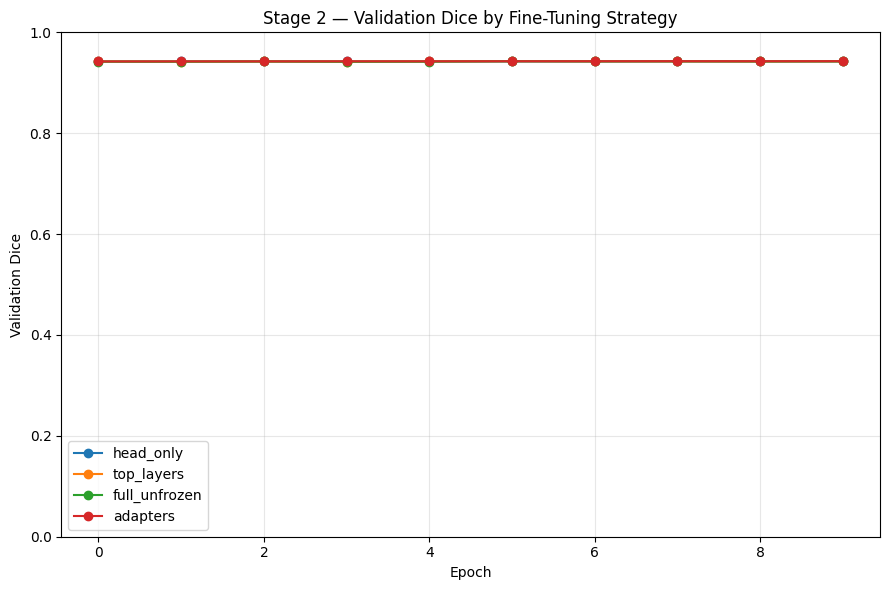

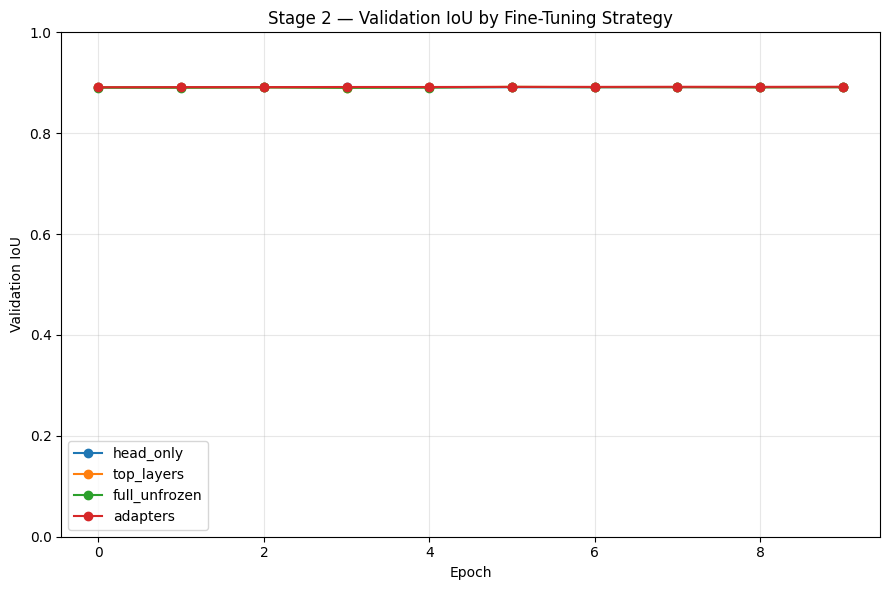

In [23]:
# ============================================================
# VALIDATION CURVES
# ============================================================
plt.figure(figsize=(9, 6))
for strategy in STRATEGIES:
    hdf = history_frames[strategy]
    plt.plot(hdf["val_dice_coef"].values, marker="o", label=strategy)
plt.xlabel("Epoch")
plt.ylabel("Validation Dice")
plt.title("Stage 2 — Validation Dice by Fine-Tuning Strategy")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(EXP_DIR / "stage2_val_dice_curves.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 6))
for strategy in STRATEGIES:
    hdf = history_frames[strategy]
    plt.plot(hdf["val_iou_coef"].values, marker="o", label=strategy)
plt.xlabel("Epoch")
plt.ylabel("Validation IoU")
plt.title("Stage 2 — Validation IoU by Fine-Tuning Strategy")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(EXP_DIR / "stage2_val_iou_curves.png", dpi=150)
plt.show()


## Parameter-efficiency comparison


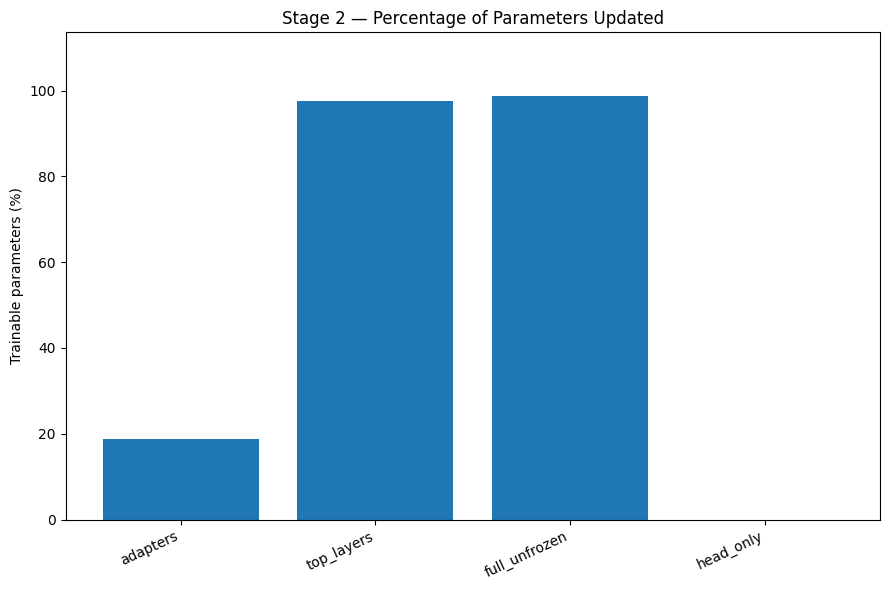

     strategy  trainable_params  total_params  trainable_ratio  val_dice  val_iou
     adapters             55465        294548         0.188305  0.942842 0.892099
   top_layers            233521        239100         0.976667  0.942741 0.891914
full_unfrozen            236156        239100         0.987687  0.942658 0.891766
    head_only                17        239100         0.000071  0.942369 0.891250


In [24]:
# ============================================================
# TRAINABLE-PARAMETER COMPARISON
# ============================================================
plot_df = summary_df.copy()
plot_df["trainable_percent"] = plot_df["trainable_ratio"] * 100

plt.figure(figsize=(9, 6))
x = np.arange(len(plot_df))
plt.bar(x, plot_df["trainable_percent"])
plt.xticks(x, plot_df["strategy"], rotation=25, ha="right")
plt.ylabel("Trainable parameters (%)")
plt.title("Stage 2 — Percentage of Parameters Updated")
plt.ylim(0, max(100, float(plot_df["trainable_percent"].max()) * 1.15))
plt.tight_layout()
plt.savefig(EXP_DIR / "stage2_trainable_parameter_percentage.png", dpi=150)
plt.show()

print(summary_df[["strategy", "trainable_params", "total_params", "trainable_ratio", "val_dice", "val_iou"]].to_string(index=False))


## Final artifact verification


In [25]:
# ============================================================
# VERIFY ALL FOUR CHECKPOINTS / HISTORIES / MODELS
# ============================================================
assert STAGE1_CHECKPOINT.exists(), "Stage-1 source checkpoint is missing."

for strategy in STRATEGIES:
    var_dir = EXP_DIR / strategy
    ckpt = var_dir / f"{strategy}_best.weights.h5"
    hist = var_dir / f"{strategy}_history.csv"
    model_file = var_dir / f"{strategy}.keras"

    assert ckpt.exists(), f"Missing checkpoint: {ckpt}"
    assert hist.exists(), f"Missing history: {hist}"
    assert model_file.exists(), f"Missing model file: {model_file}"

print("=" * 80)
print("STAGE 2 COMPLETE — ALL 4 ARTIFACT SETS VERIFIED")
print("=" * 80)
print("Starting checkpoint:", STAGE1_CHECKPOINT)
print("Starting checkpoint filename:", STAGE1_CHECKPOINT.name)
print("SHA-256:", STAGE1_SHA256)
print("Output directory:", EXP_DIR)
print("\nFinal results:")
print(
    summary_df[
        ["strategy", "val_dice", "val_iou",
         "trainable_params", "total_params"]
    ].to_string(index=False)
)


STAGE 2 COMPLETE — ALL 4 ARTIFACT SETS VERIFIED
Starting checkpoint: /kaggle/input/datasets/annn51/mobile-unet-stage1-best/hp_bs_16_best.weights (1).h5
Starting checkpoint filename: hp_bs_16_best.weights (1).h5
SHA-256: 94858fbcd9fa86762a4099e2578a668bb853185a8d352de1a085610634efaea4
Output directory: /kaggle/working/Segmentation Output/stage2_finetuning_experiments

Final results:
     strategy  val_dice  val_iou  trainable_params  total_params
     adapters  0.942842 0.892099             55465        294548
   top_layers  0.942741 0.891914            233521        239100
full_unfrozen  0.942658 0.891766            236156        239100
    head_only  0.942369 0.891250                17        239100
